In [2]:
from __future__ import annotations

import math
import textwrap
import shutil
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from IPython.display import Image, display

In [3]:
DATA_DIR_NAMES = [
    'upcoding_v28_top10_ha2025_export',
]
DATA_ZIP_NAMES = [f'{name}.zip' for name in DATA_DIR_NAMES]
COEFF_NAME = 'cms_v28_cna_coefficients_export_features.csv'
SEARCH_ROOTS = []
for root in (
    Path.cwd(),
    Path.cwd() / 'data' / 'upcoding',
    Path.cwd().parent / 'data' / 'upcoding',
    Path('/content'),
    Path('/content/data/upcoding'),
):
    if root not in SEARCH_ROOTS and root.exists():
        SEARCH_ROOTS.append(root)

outputs_dir = Path('outputs')
outputs_dir.mkdir(parents=True, exist_ok=True)
OUT = outputs_dir / 'cost_matrix_construction_diagnostics_outputs'
FIG = OUT / 'figures'
DATA_OUT = OUT / 'data'
for p in (OUT, FIG, DATA_OUT):
    p.mkdir(parents=True, exist_ok=True)

In [4]:
TAU = 0.5
RHO = 0.5
RELATED_SCORE = 0.5
SIGNAL_MODERATION = 0.25
FLOOR = 0.03
ETA = 1e-6
VERSION = 'v17'

SIGNAL_MODERATED = ['hcc155', 'hcc280', 'hcc38', 'hcc93', 'hcc328', 'hcc226']
RELATED_EXTRA = ['hcc21', 'hcc23', 'hcc35', 'hcc62', 'hcc64', 'hcc264', 'hcc267', 'hcc327']
MANUAL_BLOCKS = [
    ('Diabetes model branch', ['hcc36', 'hcc37', 'hcc38']),
    ('Heart failure model branch', ['hcc224', 'hcc225', 'hcc226']),
    ('CKD model branch', ['hcc328', 'hcc329']),
    ('Substance-use model branch', ['hcc137', 'hcc138', 'hcc139']),
    ('Mental-health model branch', ['hcc151', 'hcc152', 'hcc153', 'hcc154', 'hcc155']),
    ('Vascular disease model branch', ['hcc263', 'hcc264', 'hcc267']),
    ('Cancer model branch', ['hcc20', 'hcc21', 'hcc22', 'hcc23']),
]

HCC_SHORT = {
    'hcc1': 'HIV',
    'hcc2': 'Sepsis',
    'hcc20': 'Lung cancer',
    'hcc21': 'Lymphoma',
    'hcc22': 'Bladder/colorectal cancer',
    'hcc23': 'Prostate/breast tumors',
    'hcc35': 'Pancreas transplant',
    'hcc36': 'Diabetes acute',
    'hcc37': 'Diabetes chronic',
    'hcc38': 'Diabetes',
    'hcc48': 'Morbid obesity',
    'hcc51': 'Endocrine disorders',
    'hcc62': 'Liver transplant',
    'hcc64': 'Cirrhosis',
    'hcc65': 'Chronic hepatitis',
    'hcc77': 'Intestine transplant',
    'hcc78': 'Intestinal obstruction',
    'hcc93': 'RA',
    'hcc109': 'Hemolytic/aplastic anemia',
    'hcc112': 'Coagulation',
    'hcc137': 'Drug use',
    'hcc139': 'Alcohol use',
    'hcc154': 'Bipolar',
    'hcc155': 'Depression',
    'hcc182': 'Spinal cord disorders',
    'hcc221': 'Heart transplant',
    'hcc224': 'Acute-on-chronic HF',
    'hcc225': 'Acute HF',
    'hcc226': 'Heart failure',
    'hcc228': 'Acute MI',
    'hcc238': 'Arrhythmia',
    'hcc249': 'Stroke',
    'hcc253': 'Hemiplegia',
    'hcc264': 'Vascular disease',
    'hcc267': 'DVT/PE',
    'hcc276': 'Lung transplant',
    'hcc280': 'COPD/lung',
    'hcc300': 'Macular degeneration',
    'hcc327': 'CKD stage 4',
    'hcc328': 'CKD stage 3B',
    'hcc329': 'CKD stage 3',
    'hcc398': 'Head injury',
}

CATEGORY_COLORS = {
    'baseline floor': '#9ecae1',
    'pre-specified diagonal score': '#bcbddc',
    'coding-sensitive group score': '#fdae6b',
    'signal-moderated top-ten groups': '#31a354',
}

plt.rcParams.update({
    'font.size': 8.5,
    'axes.titlesize': 9.5,
    'axes.labelsize': 8.8,
    'xtick.labelsize': 8.0,
    'ytick.labelsize': 8.0,
    'legend.fontsize': 7.5,
    'figure.titlesize': 9.5,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

In [5]:
# Helper functions
def resolve_data_dir() -> Path:
    searched = []
    for root in SEARCH_ROOTS:
        for name in DATA_DIR_NAMES:
            candidate = root / name
            searched.append(str(candidate))
            if (candidate / 'baseline_hier.csv').exists():
                return candidate
    for root in SEARCH_ROOTS:
        for name in DATA_ZIP_NAMES:
            zip_path = root / name
            searched.append(str(zip_path))
            if zip_path.exists():
                work = OUT / '_unzipped'
                if work.exists():
                    shutil.rmtree(work)
                work.mkdir(parents=True, exist_ok=True)
                with zipfile.ZipFile(zip_path) as z:
                    z.extractall(work)
                for candidate in work.rglob('baseline_hier.csv'):
                    return candidate.parent
    raise FileNotFoundError(
        'Could not find the upcoding export folder or zip. Searched: ' + ', '.join(searched)
    )

def resolve_coeff_path() -> Path:
    searched = []
    for root in SEARCH_ROOTS:
        candidate = root / COEFF_NAME
        searched.append(str(candidate))
        if candidate.exists():
            return candidate
    raise FileNotFoundError(
        'Could not find the coefficient CSV. Searched: ' + ', '.join(searched)
    )

def parse_group_hccs(s) -> list[str]:
    if pd.isna(s):
        return []
    s = str(s).replace('HCC', 'hcc').replace(' ', '')
    return [p for p in s.split(',') if p.startswith('hcc')]


def short_label(feature: str, desc_map: dict[str, str]) -> str:
    if feature in HCC_SHORT:
        return HCC_SHORT[feature]
    desc = desc_map.get(feature, '')
    if not desc:
        return feature.upper()
    return textwrap.shorten(desc, width=28, placeholder='...')


def get_target_rows(target_map: pd.DataFrame, features_all: list[str], coeff: pd.DataFrame) -> pd.DataFrame:
    rows = []
    if {'diagnosis_group', 'health_affairs_group_hccs', 'removal_effect_percent'}.issubset(target_map.columns):
        raw = target_map['removal_effect_percent'].astype(float).to_numpy()
        denom = float(np.nanmax(raw)) if np.nanmax(raw) > 0 else 1.0
        for _, r in target_map.iterrows():
            members = parse_group_hccs(r.get('health_affairs_group_hccs', ''))
            if not members:
                target = str(r.get('target_hcc', r.get('hcc', '')))
                members = [target] if target.startswith('hcc') else []
            rows.append({
                'diagnosis_group': str(r['diagnosis_group']),
                'members': members,
                'target_hcc': str(r.get('target_hcc', members[0] if members else '')),
                'score_raw': float(r['removal_effect_percent']),
                'score': float(r['removal_effect_percent']) / denom,
                'source': 'health-affairs-risk-contribution',
            })
        return pd.DataFrame(rows)

    if {'v22_label', 'hcc', 'ma_prev', 'tm_prev'}.issubset(target_map.columns):
        tmp = target_map.copy()
        tmp['lift_weight'] = tmp.get('lift_weight', 1.0)
        raw_scores = []
        for _, r in tmp.iterrows():
            h = str(r['hcc'])
            coef = float(coeff.loc[h, 'cna_coef']) if h in coeff.index else 1.0
            raw_scores.append(max(float(r['ma_prev']) - float(r['tm_prev']), 0.0) * float(r['lift_weight']) * abs(coef))
        denom = max(raw_scores) if max(raw_scores) > 0 else 1.0
        for raw, (_, r) in zip(raw_scores, tmp.iterrows()):
            h = str(r['hcc'])
            rows.append({
                'diagnosis_group': str(r['v22_label']),
                'members': [h],
                'target_hcc': h,
                'score_raw': raw,
                'score': raw / denom,
                'source': 'ma-tm-prevalence-lift-times-signal',
            })
        return pd.DataFrame(rows)

    raise ValueError('Unrecognized target_mapping_table.csv format.')


Wrote outputs to /mnt/nfs/CX900004_DS17/strategic-feature-selection/notebooks/outputs/cost_matrix_construction_diagnostics_outputs
Bundle: /mnt/nfs/CX900004_DS17/strategic-feature-selection/notebooks/outputs/cost_matrix_construction_diagnostics_outputs.zip
Figure PDF: outputs/cost_matrix_construction_diagnostics_outputs/figures/cost_matrix_construction_diagnostics.pdf
Figure PNG: outputs/cost_matrix_construction_diagnostics_outputs/figures/cost_matrix_construction_diagnostics.png


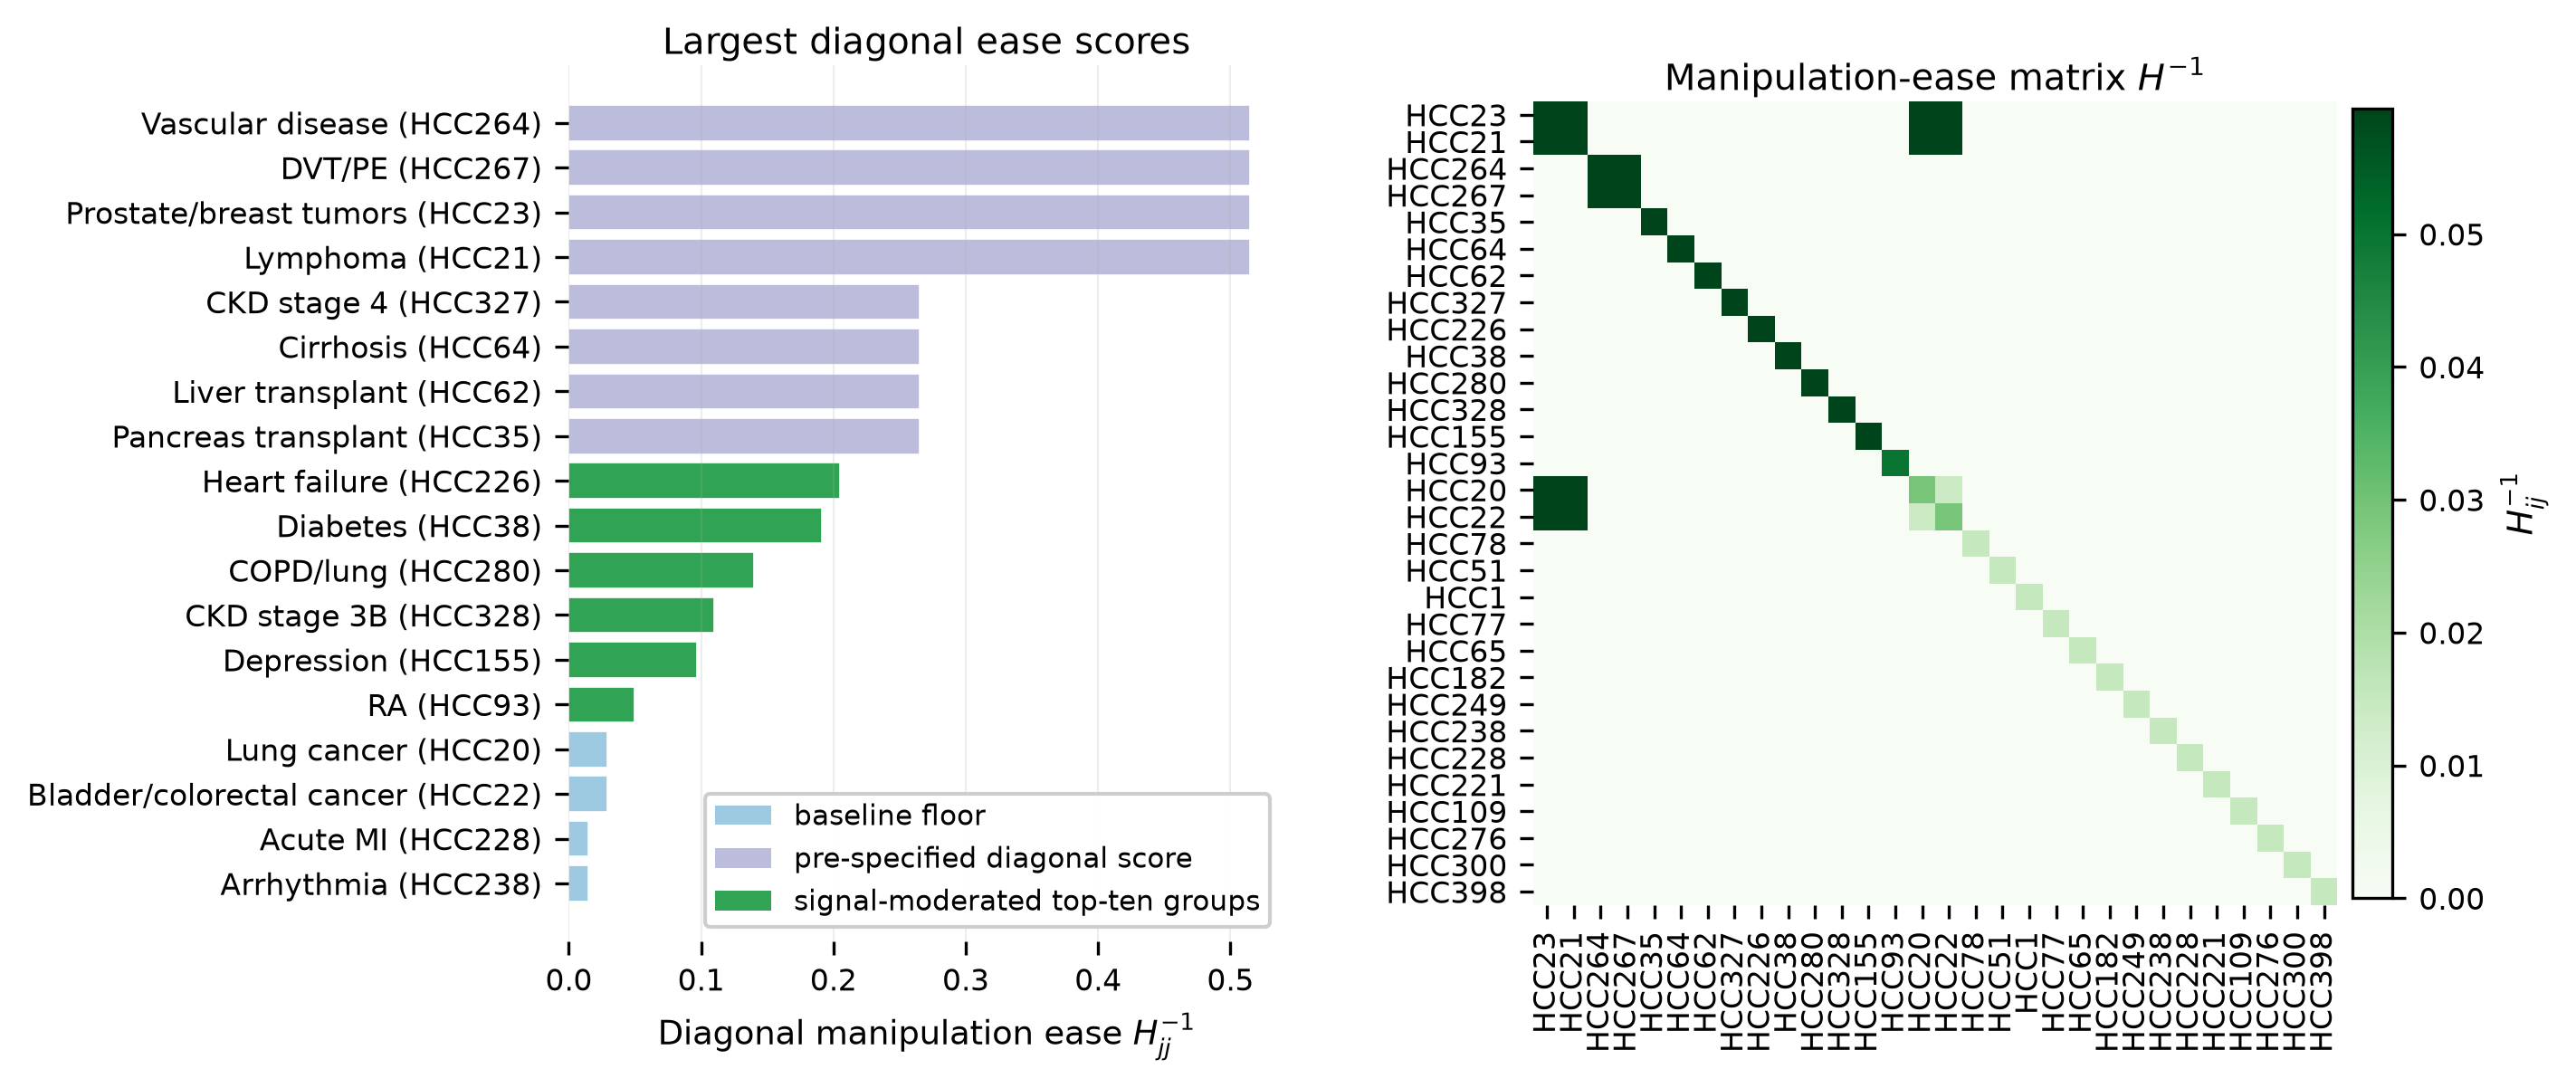

In [6]:
class CaseStudyCostConstruction:
    def __init__(self, data_dir: Path):
        self.data_dir = data_dir
        self.base = pd.read_csv(data_dir / 'baseline_hier.csv')
        self.target_map = pd.read_csv(data_dir / 'target_mapping_table.csv')
        self.coeff = pd.read_csv(resolve_coeff_path()).set_index('feature')
        self.features_all = [c for c in self.base.columns if c != 'person_id']
        X_all_raw = self.base[self.features_all].astype(float).values
        self.prev_all = X_all_raw.mean(axis=0)
        self.active_idx = np.where(self.prev_all > 0)[0]
        self.features = [self.features_all[i] for i in self.active_idx]
        theta_all = np.zeros(len(self.features_all))
        self.desc_map = {f: '' for f in self.features_all}
        for i, f in enumerate(self.features_all):
            if f in self.coeff.index:
                theta_all[i] = float(self.coeff.loc[f, 'cna_coef'])
                self.desc_map[f] = str(self.coeff.loc[f, 'description'])
        self.theta = theta_all[self.active_idx]
        self.build_cost_matrix()

    def build_cost_matrix(self):
        target_rows = get_target_rows(self.target_map, self.features_all, self.coeff)
        D_raw_all = np.full(len(self.features_all), FLOOR)
        group_blocks = []
        self.top_members = set()
        self.top_group = {}
        self.top_score = {}

        for _, row in target_rows.iterrows():
            score = float(row['score'])
            members = [m for m in row['members'] if isinstance(m, str) and m in self.features_all]
            group_name = str(row['diagnosis_group'])
            if members:
                group_blocks.append((group_name, members))
            for f in members:
                j = self.features_all.index(f)
                D_raw_all[j] = max(D_raw_all[j], FLOOR + score)
                self.top_members.add(f)
                self.top_group[f] = group_name
                self.top_score[f] = score

        for f in RELATED_EXTRA:
            if f in self.features_all:
                j = self.features_all.index(f)
                D_raw_all[j] = max(D_raw_all[j], FLOOR + RELATED_SCORE)

        D_final_all = D_raw_all.copy()
        for f in SIGNAL_MODERATED:
            if f in self.features_all:
                j = self.features_all.index(f)
                D_final_all[j] = FLOOR + SIGNAL_MODERATION * (D_final_all[j] - FLOOR)

        block_defs = group_blocks + MANUAL_BLOCKS
        seen, block_defs_unique = set(), []
        for name, members in block_defs:
            key = tuple(sorted(members))
            if key in seen:
                continue
            seen.add(key)
            block_defs_unique.append((name, members))

        B_all = np.zeros((len(self.features_all), len(self.features_all)))
        block_records = []
        for block_id, (name, members) in enumerate(block_defs_unique, start=1):
            idx = [self.features_all.index(f) for f in members if f in self.features_all]
            for f in members:
                if f in self.features_all:
                    block_records.append({
                        'block_id': block_id,
                        'block_name': name,
                        'feature': f,
                        'description': self.desc_map.get(f, ''),
                        'active': f in self.features,
                        'coding_sensitive': f in self.top_members,
                        'signal_moderated': f in SIGNAL_MODERATED,
                        'pre_specified_diagonal_score': f in RELATED_EXTRA,
                    })
            if len(idx) >= 2:
                v = np.zeros(len(self.features_all))
                for j in idx:
                    v[j] = math.sqrt(max(D_final_all[j], FLOOR))
                B_all += np.outer(v, v)

        self.D_all = D_final_all
        self.B_all = B_all
        self.D = D_final_all[self.active_idx]
        self.B = B_all[np.ix_(self.active_idx, self.active_idx)]
        if np.max(np.diag(self.B)) > 0:
            self.B = self.B / np.max(np.diag(self.B))
        self.Hinv = TAU * (np.diag(self.D) + RHO * self.B) + ETA * np.eye(len(self.features))
        self.H = np.linalg.inv(self.Hinv)
        self.block_records = pd.DataFrame(block_records)

        block_rows = []
        for block_id, (name, members) in enumerate(block_defs_unique, start=1):
            row = {'block_id': block_id, 'block_name': name}
            for f in self.features:
                row[f] = int(f in members)
            block_rows.append(row)
        self.block_mat = pd.DataFrame(block_rows)

        comp_rows = []
        for pos, f in enumerate(self.features):
            category = 'baseline floor'
            if f in RELATED_EXTRA and f not in self.top_members:
                category = 'pre-specified diagonal score'
            if f in self.top_members:
                category = 'coding-sensitive group score'
            if f in SIGNAL_MODERATED:
                category = 'signal-moderated top-ten groups'
            j = self.features_all.index(f)
            comp_rows.append({
                'feature': f,
                'label': short_label(f, self.desc_map),
                'description': self.desc_map.get(f, ''),
                'baseline_prevalence': float(self.prev_all[j]),
                'theta_star': float(self.theta[pos]),
                'abs_theta_star': abs(float(self.theta[pos])),
                'top10_group': self.top_group.get(f, ''),
                'coding_sensitive': f in self.top_members,
                'group_score': float(self.top_score.get(f, np.nan)) if f in self.top_score else np.nan,
                'D_final': float(self.D[pos]),
                'B_diag': float(self.B[pos, pos]),
                'Hinv_diag': float(self.Hinv[pos, pos]),
                'category': category,
                'signal_moderated': f in SIGNAL_MODERATED,
                'pre_specified_diagonal_score': f in RELATED_EXTRA,
                'active': True,
            })
        self.component_df = pd.DataFrame(comp_rows)


def write_cost_outputs(problem: CaseStudyCostConstruction):
    problem.component_df.to_csv(DATA_OUT / 'cost_component_active_hccs.csv', index=False)
    problem.block_records.to_csv(DATA_OUT / 'block_family_membership_long.csv', index=False)
    problem.block_mat.to_csv(DATA_OUT / 'block_family_membership_active_matrix.csv', index=False)
    pd.DataFrame(problem.Hinv, index=problem.features, columns=problem.features).to_csv(DATA_OUT / 'constructed_Hinv_active.csv')
    pd.DataFrame(problem.H, index=problem.features, columns=problem.features).to_csv(DATA_OUT / 'constructed_H_active.csv')
    pd.DataFrame(problem.B, index=problem.features, columns=problem.features).to_csv(DATA_OUT / 'block_component_B_active.csv')


def plot_cost_matrix_diagnostics_custom(comp: pd.DataFrame, Hinv_df: pd.DataFrame, version: str = VERSION):
    fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.2), gridspec_kw={'width_ratios': [1.0, 1.2]})

    ax = axes[0]
    dat = comp.sort_values('Hinv_diag', ascending=True).tail(min(18, len(comp)))
    y = np.arange(len(dat))
    ax.barh(
        y,
        dat['Hinv_diag'],
        color=[CATEGORY_COLORS.get(c, '#cccccc') for c in dat['category']],
        edgecolor='white',
        linewidth=0.4,
    )
    ax.set_yticks(y)
    ax.set_yticklabels([f'{r.label} ({r.feature.upper()})' for _, r in dat.iterrows()])
    ax.set_xlabel(r'Diagonal manipulation ease $H^{-1}_{jj}$')
    ax.set_title('Largest diagonal ease scores', loc='center', pad=3, fontsize=9.6)
    ax.grid(axis='x', alpha=0.22, linewidth=0.5)
    present = [c for c in CATEGORY_COLORS if c in set(comp['category'])]
    ax.legend(
        handles=[Patch(facecolor=CATEGORY_COLORS[c], edgecolor='none', label=c) for c in present],
        loc='lower right',
        frameon=True,
        framealpha=0.96,
        borderpad=0.35,
    )

    ax = axes[1]
    order = comp.sort_values('Hinv_diag', ascending=False)['feature'].tolist()
    Hord = Hinv_df.loc[order, order].values
    vmax = np.percentile(Hord, 98) if Hord.size else 1
    im = ax.imshow(Hord, aspect='equal', cmap='Greens', vmin=0, vmax=vmax, interpolation='nearest')
    ax.set_title(r'Manipulation-ease matrix $H^{-1}$', loc='center', pad=3, fontsize=9.6)
    ax.set_xticks(np.arange(len(order)))
    ax.set_yticks(np.arange(len(order)))
    short = [f.upper() for f in order]
    ax.set_xticklabels(short, rotation=90, fontsize=8.0)
    ax.set_yticklabels(short, fontsize=8.0)
    cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.018)
    cb.set_label(r'$H^{-1}_{ij}$', fontsize=9.0)
    cb.ax.tick_params(labelsize=8.0)

    for ax in axes:
        for spine in ax.spines.values():
            spine.set_visible(False)

    fig.tight_layout(w_pad=5.0)
    for ext in ['png', 'pdf']:
        fig.savefig(FIG / f'cost_matrix_construction_diagnostics.{ext}', dpi=300, bbox_inches='tight')
    plt.close(fig)


def main():
    data_dir = resolve_data_dir()
    resolve_coeff_path()
    problem = CaseStudyCostConstruction(data_dir)
    write_cost_outputs(problem)
    comp = problem.component_df
    Hinv_df = pd.DataFrame(problem.Hinv, index=problem.features, columns=problem.features)
    plot_cost_matrix_diagnostics_custom(comp, Hinv_df, version=VERSION)
    zip_path = shutil.make_archive(str(OUT), 'zip', OUT)
    print(f'Wrote outputs to {OUT.resolve()}')
    print(f'Bundle: {zip_path}')
    print('Figure PDF:', FIG / f'cost_matrix_construction_diagnostics.pdf')
    print('Figure PNG:', FIG / f'cost_matrix_construction_diagnostics.png')


if __name__ == '__main__':
    main()
    display(Image(filename=str(FIG / f'cost_matrix_construction_diagnostics.png')))
